# Exp 1: Baseline (EfficientNet-V2-S, Freeze Backbone)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

if torch.cuda.is_available():
    print("CUDA")

CUDA


## 1. Data Preprocessing & DataLoader

In [3]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder("../data/train", transform=train_transform)
val_dataset   = datasets.ImageFolder("../data/val", transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(train_dataset.classes)
print(len(train_dataset), len(val_dataset))

['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
8168 1750


## 2. Model Setup - Baseline

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.efficientnet_v2_s(weights="DEFAULT")

for param in model.features.parameters():
    param.requires_grad = False

# เปลี่ยน Classifier ท้ายสุดเป็น 12 คลาส
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(in_features=1280, out_features=12)
)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

In [5]:
print(model.classifier)
print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total params:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=12, bias=True)
)
Trainable params: 15372
Total params: 20192860


## 3. Training & Validation Loop

In [6]:
history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}

def train(num_epochs):
    for epoch in range(num_epochs):
        model.train()
        train_loss, train_correct = 0.0, 0
        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()

        model.eval()
        val_loss, val_correct = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()

        history['loss'].append(train_loss / len(train_dataset))
        history['accuracy'].append(train_correct / len(train_dataset))
        history['val_loss'].append(val_loss / len(val_dataset))
        history['val_accuracy'].append(val_correct / len(val_dataset))
        print(f"Epoch {len(history['loss']):02d} | "
              f"Train Loss: {history['loss'][-1]:.4f} Acc: {history['accuracy'][-1]:.4f} | "
              f"Val Loss: {history['val_loss'][-1]:.4f} Acc: {history['val_accuracy'][-1]:.4f}")

In [7]:
# train head
train(5)

Epoch 1: 100%|██████████| 256/256 [02:03<00:00,  2.08it/s]


Epoch 01 | Train Loss: 0.7968 Acc: 0.8000 | Val Loss: 0.4504 Acc: 0.8731


Epoch 2: 100%|██████████| 256/256 [02:00<00:00,  2.13it/s]


Epoch 02 | Train Loss: 0.4182 Acc: 0.8790 | Val Loss: 0.3625 Acc: 0.8949


Epoch 3: 100%|██████████| 256/256 [02:02<00:00,  2.10it/s]


Epoch 03 | Train Loss: 0.3487 Acc: 0.8946 | Val Loss: 0.3151 Acc: 0.9057


Epoch 4: 100%|██████████| 256/256 [02:00<00:00,  2.12it/s]


Epoch 04 | Train Loss: 0.3214 Acc: 0.8991 | Val Loss: 0.2986 Acc: 0.9080


Epoch 5: 100%|██████████| 256/256 [01:59<00:00,  2.15it/s]


Epoch 05 | Train Loss: 0.2964 Acc: 0.9088 | Val Loss: 0.2715 Acc: 0.9097


In [9]:
# train all
for param in model.parameters():
    param.requires_grad = True
optimizer = optim.Adam(model.parameters(), lr=0.0001)
train(10)

Epoch 1: 100%|██████████| 256/256 [02:08<00:00,  1.99it/s]


Epoch 06 | Train Loss: 0.1918 Acc: 0.9376 | Val Loss: 0.0931 Acc: 0.9680


Epoch 2: 100%|██████████| 256/256 [02:03<00:00,  2.07it/s]


Epoch 07 | Train Loss: 0.0662 Acc: 0.9782 | Val Loss: 0.0864 Acc: 0.9697


Epoch 3: 100%|██████████| 256/256 [01:46<00:00,  2.41it/s]


Epoch 08 | Train Loss: 0.0354 Acc: 0.9887 | Val Loss: 0.1013 Acc: 0.9686


... (10 outputs left out)

Epoch 9: 100%|██████████| 256/256 [01:40<00:00,  2.56it/s]


Epoch 14 | Train Loss: 0.0152 Acc: 0.9958 | Val Loss: 0.0912 Acc: 0.9777


Epoch 10: 100%|██████████| 256/256 [01:41<00:00,  2.53it/s]


Epoch 15 | Train Loss: 0.0193 Acc: 0.9934 | Val Loss: 0.0954 Acc: 0.9749


## 4. Evaluation

In [10]:
def plot_history(history):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history['accuracy'])
    plt.plot(history['val_accuracy'])
    plt.title('Model Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    plt.subplot(1, 2, 2)
    plt.plot(history['loss'])
    plt.plot(history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()


def evaluate(model, loader, class_names):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            y_pred += model(inputs.to(device)).argmax(1).cpu().tolist()
            y_true += labels.tolist()

    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=class_names).plot(
        xticks_rotation=45, cmap="Blues", colorbar=False)
    plt.tight_layout()
    plt.show()
    return np.array(y_true), np.array(y_pred)


def plot_wrong(dataset, y_true, y_pred, class_names, n=12):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    wrong = np.where(y_true != y_pred)[0][:n]
    plt.figure(figsize=(14, 7))
    for k, i in enumerate(wrong):
        img = dataset[i][0].permute(1, 2, 0).numpy() * std + mean
        plt.subplot(3, 4, k + 1)
        plt.imshow(np.clip(img, 0, 1))
        plt.xticks([])
        plt.yticks([])
        plt.xlabel(f"{class_names[y_pred[i]]} (true: {class_names[y_true[i]]})", color="red")
    plt.tight_layout()
    plt.show()

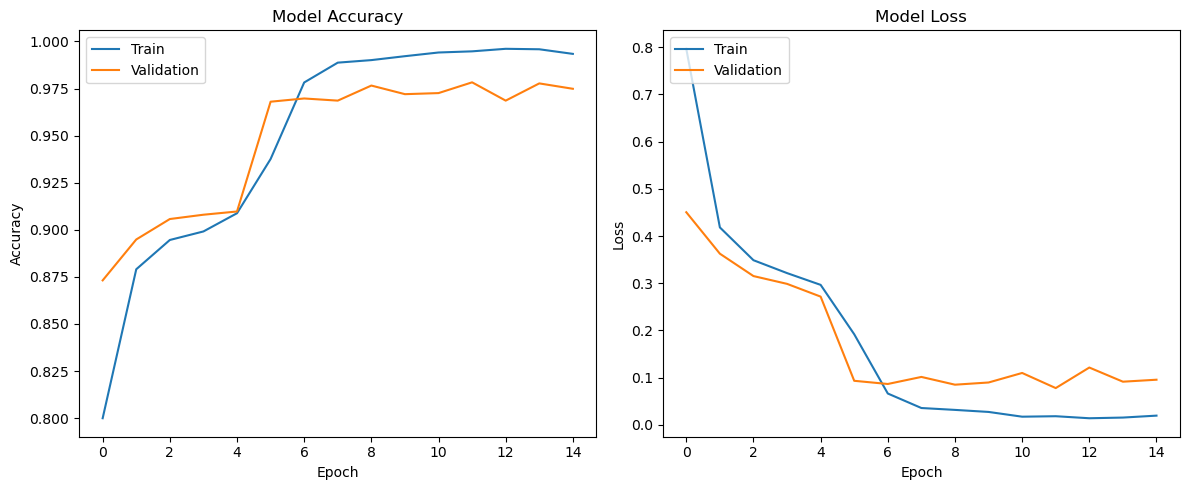

              precision    recall  f1-score   support

     battery     0.9789    0.9789    0.9789       142
  biological     0.9800    0.9932    0.9866       148
 brown-glass     0.9778    0.9670    0.9724        91
   cardboard     0.9846    0.9624    0.9734       133
     clothes     0.9955    0.9867    0.9911       225
 green-glass     0.9674    0.9674    0.9674        92
       metal     0.9231    0.9391    0.9310       115
       paper     0.9625    0.9809    0.9716       157
     plastic     0.9323    0.9538    0.9430       130
       shoes     0.9932    0.9932    0.9932       296
       trash     0.9811    0.9905    0.9858       105
 white-glass     0.9820    0.9397    0.9604       116

    accuracy                         0.9749      1750
   macro avg     0.9715    0.9711    0.9712      1750
weighted avg     0.9751    0.9749    0.9749      1750



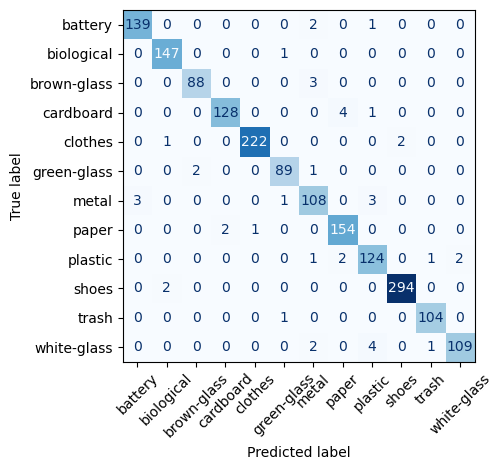

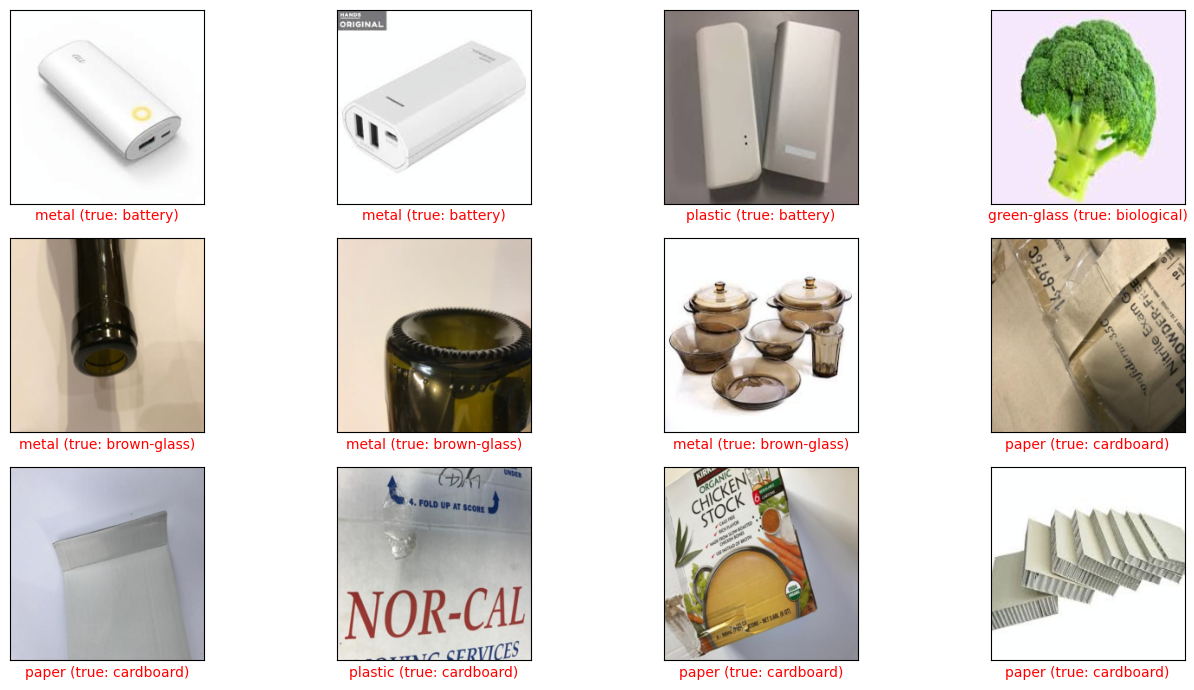

In [11]:
plot_history(history)
y_true, y_pred = evaluate(model, val_loader, val_dataset.classes)
plot_wrong(val_dataset, y_true, y_pred, val_dataset.classes)

1751
              precision    recall  f1-score   support

     battery     0.9859    0.9859    0.9859       142
  biological     0.9669    0.9865    0.9766       148
 brown-glass     0.9778    0.9670    0.9724        91
   cardboard     0.9848    0.9701    0.9774       134
     clothes     0.9955    0.9867    0.9911       225
 green-glass     0.9677    0.9783    0.9730        92
       metal     0.9561    0.9478    0.9520       115
       paper     0.9748    0.9810    0.9779       158
     plastic     0.9474    0.9767    0.9618       129
       shoes     0.9932    0.9865    0.9899       297
       trash     0.9905    1.0000    0.9952       104
 white-glass     0.9825    0.9655    0.9739       116

    accuracy                         0.9794      1751
   macro avg     0.9769    0.9777    0.9773      1751
weighted avg     0.9796    0.9794    0.9795      1751



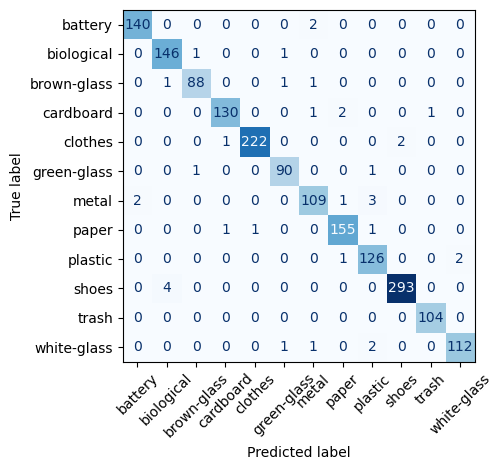

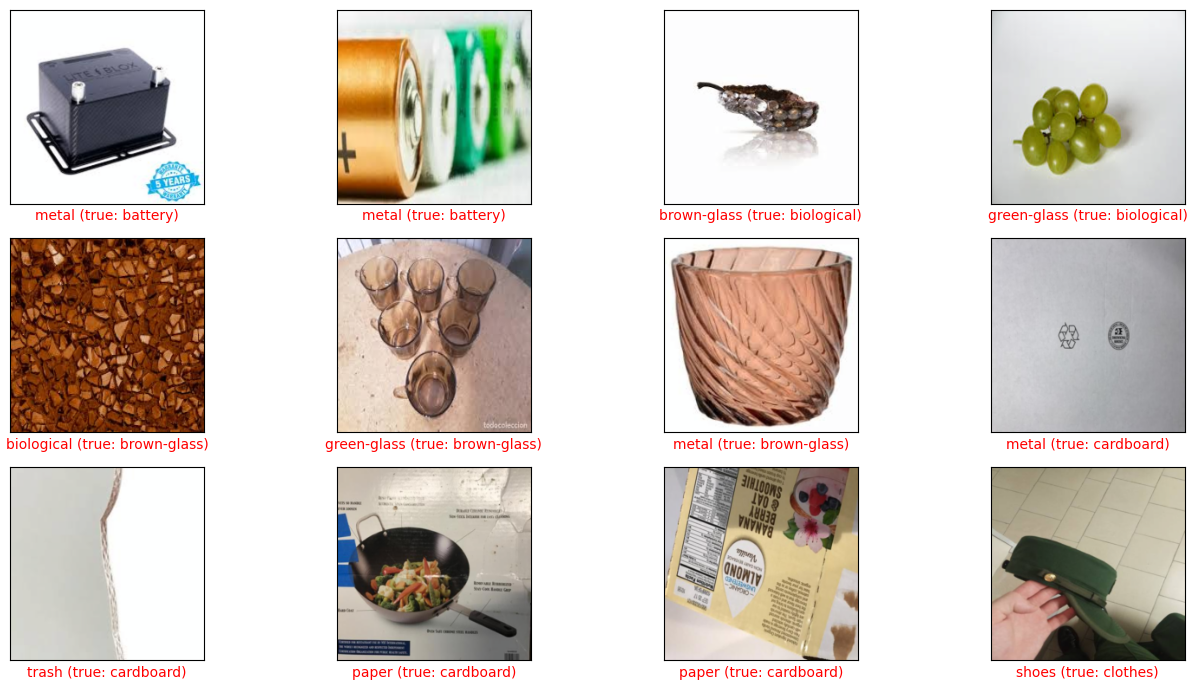

In [12]:
test_dataset = datasets.ImageFolder("../data/test", transform=val_transform)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)
print(len(test_dataset))

y_true, y_pred = evaluate(model, test_loader, test_dataset.classes)
plot_wrong(test_dataset, y_true, y_pred, test_dataset.classes)

In [13]:
torch.save(model.state_dict(), "../saves/v3_two_stage.pth")

In [15]:
print(model)

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): FusedMBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): FusedMBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  